In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import patsy
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, GammaRegressor
from joblib import Parallel, delayed, parallel_config
from matplotlib import pyplot as plt
import cartopy.crs as ccrs

# Put the repo root (case_studies/) on the import path so `argo` is importable
sys.path.insert(0, str(Path.cwd().parents[1]))
from argo.read import lat, lon, temp, psal, day, pressure

# Figures sized for a Google Docs page (6.5 in text width); PNGs saved to figures/ for pasting
PAGE_W = 6.5
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "figure.dpi": 150, "savefig.dpi": 300})
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)


## Data quality

A few profiles have physically impossible salinity. For example, one float near 1°S, 230°E reads about 24 psu at 1500 dbar, where every neighboring profile reads 34.60. Others read 35.8–38.9 psu at depth. Deep Pacific water at 1500 dbar is very uniform, so we drop any profile whose 1500-dbar salinity is outside [34.3, 34.9]. This removes 84 of 49,583 profiles (0.17%). A range check at all depths would be wrong, because it would flag genuine North Pacific Intermediate Water near 34.0 psu at about 700 dbar.


In [2]:
keep = (psal[-1] >= 34.3) & (psal[-1] <= 34.9)
print(f"QC: dropping {(~keep).sum()} of {keep.size} profiles")
lat, lon, day = lat[keep], lon[keep] % 360, np.asarray(day)[keep]   # lon on 0-360: no break at the dateline
temp, psal = temp[:, keep], psal[:, keep]
profiles = {"temp": temp.T, "psal": psal.T}   # (n_profiles, n_depths)
n_depths = len(pressure)


QC: dropping 84 of 49583 profiles


# Analysis

Each temperature and salinity profile is a curve over 100 depths. We summarize each curve with a few functional principal components, then ask how the temperature and salinity components co-vary, conditional on location and time $x = (\text{lat}, \text{lon}, \text{day})$:

$$\rho_k(x) = \operatorname{corr}\big(\xi^T_k, \xi^S_k \mid x\big),$$

where $\xi^T_k$ and $\xi^S_k$ are the $k$-th component scores of a profile's temperature and salinity curves.

1. **Functional representation.** For each variable, subtract the mean profile and divide by **one** overall SD, not a separate SD at each depth, so the components keep their physical meaning as departures of the whole curve from the mean profile. Then run PCA (an empirical Karhunen–Loève expansion) and keep $K = 10$ components for each variable. Each component's sign is set so that its largest loading is positive.
2. **Conditional mean.** OLS of the 10 scores on a three-way tensor-product spline in (lat, lon, day), with day as a cyclic spline (10 × 10 × 3 = 300 columns).
3. **Conditional SD.** For each component, a gamma GLM with a log link on the squared residual score, using a smaller 6 × 6 × 3 design. The log link keeps the variances positive.
4. **Conditional correlation.** For each pair $k$, $\operatorname{atanh}\rho_k(x) = x'\gamma_k$: a linear model for Fisher's $z$-transform of $\rho$, which keeps $\rho$ in $(-1, 1)$. It's fitted by maximum likelihood on the standardized residual scores, assuming they're bivariate normal, using Fisher scoring (information $1 + \rho^2$ per observation). See Anderson (2003), *An Introduction to Multivariate Statistical Analysis*, on Fisher's $z$, and Rigby & Stasinopoulos (2005, *JRSS-C*) on regression models for every parameter of a distribution.
5. **Uncertainty.** Profile bootstrap, B = 200: resample whole profiles with replacement and refit steps 2–4. The PCA loadings stay fixed. Refitting PCA in each replicate could flip a component's sign or swap the order of components with similar variance, which would make $\rho_k$ incomparable across replicates. Wald SEs from the Fisher information are shown for comparison.
6. **Back to the original scale.** Each fitted quantity maps back to °C and psu through the loadings: the mean profile is $\bar f + s\,(\hat\xi(x)' \phi)$, and component $k$ moves the curve by $s\,\sigma_k(x)\,\phi_k(d)$ per SD.

Components are paired by index: temperature component $k$ with salinity component $k$. We analyze components 1–6, but only the first three can be read as like-for-like pairs. The loadings below show that temperature and salinity components 1–3 have nearly the same depth shape, so $\rho_1$–$\rho_3$ ask whether the same kind of anomaly in the two variables moves together. Components 4–6 differ in shape between the variables. For example, temperature component 4 is positive at the surface while salinity component 4 is negative, and their zero crossings are at different depths. So $\rho_4$–$\rho_6$ are correlations between *different* depth patterns, and the index pairing carries no physical meaning there. Each of components 4–6 also explains only 0–3% of the variance. Past component 3, the temperature and salinity shapes diverge and in places become mirror images, which suggests they capture fine-scale structure, and some noise, rather than a mode shared by both variables. They aren't empty, though: the last section shows that component 4 carries much of the seasonal salinity signal. We keep them in the table below to show the divergence. The maps show components 1–3 only.

**Analyst choices.** $K = 10$ is fixed. The design sizes come from an earlier spatially blocked CV of a per-depth model and weren't retuned for the scores. The QC threshold is described above.

**Limitations.**
- **Matched pairs only.** Correlations between different components, such as $\xi^T_1$ with $\xi^S_2$, aren't modeled, and from component 4 on the matched pairs don't share a depth shape (see above).
- **Dependent profiles.** Profiles from the same float are treated as independent, so both the Wald and the bootstrap SEs are too small. A bootstrap that resampled whole floats would fix this.
- **Fixed basis.** The bootstrap treats the PCA loadings as known.
- **One design for all components.** Every component uses the same design, including the seasonal terms, even though seasonality matters only near the surface.


temp: cumulative variance explained [0.885 0.939 0.973 0.987 0.993 0.996 0.997 0.998 0.998 0.999]
psal: cumulative variance explained [0.811 0.91  0.95  0.976 0.985 0.991 0.994 0.995 0.996 0.997]


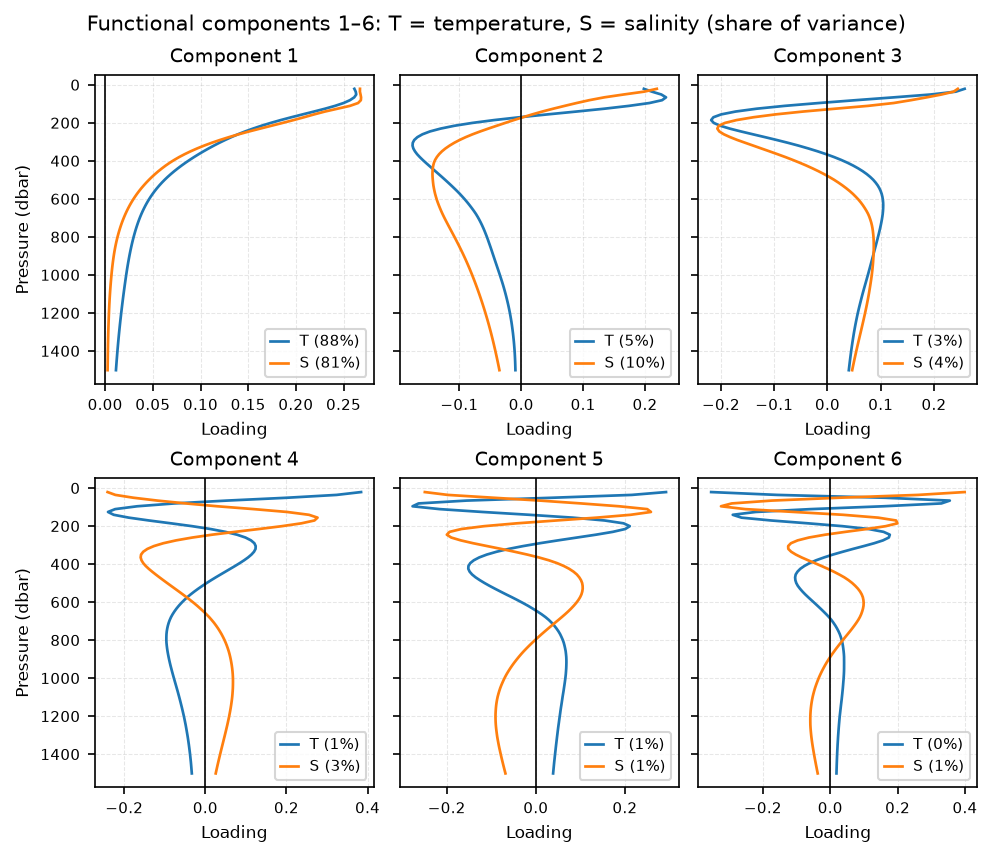

In [3]:
K = 10
fpca = {}
for v, P in profiles.items():
    m, s = P.mean(0), P.std()                     # mean profile, ONE scale for the whole curve
    pca = PCA(K).fit((P - m) / s)
    pca.components_ *= np.sign(pca.components_[np.arange(K), np.abs(pca.components_).argmax(1)])[:, None]
    fpca[v] = dict(m=m, s=s, pca=pca, scores=pca.transform((P - m) / s))
    print(f"{v}: cumulative variance explained", np.round(np.cumsum(pca.explained_variance_ratio_), 3))

fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(PAGE_W, 5.6), sharey=True, layout="constrained")
for k, a in enumerate(ax.flat):
    for c, (v, lab) in enumerate([("temp", "Temperature"), ("psal", "Salinity")]):
        f = fpca[v]["pca"]
        a.plot(f.components_[k], pressure, color=f"C{c}", linewidth=1.3, label=f"{lab[0]} ({f.explained_variance_ratio_[k]:.0%})")
    a.axvline(0, color="black", linewidth=0.8)
    a.set_title(f"Component {k + 1}"); a.set_xlabel("Loading")
    a.grid(True, alpha=0.3, linestyle="--", linewidth=0.5); a.legend(loc="lower right", handlelength=1.2)
ax[0, 0].invert_yaxis(); ax[0, 0].set_ylabel("Pressure (dbar)"); ax[1, 0].set_ylabel("Pressure (dbar)")
fig.suptitle("Functional components 1–6: T = temperature, S = salinity (share of variance)", fontsize=10)
fig.savefig(FIG_DIR / "fig1_components.png", bbox_inches="tight");


In [4]:
covars = pd.DataFrame({"lat": lat, "lon360": lon, "day": day})
B = dict(la0=lat.min() - 1e-6, la1=lat.max() + 1e-6, lo0=lon.min() - 1e-6, lo1=lon.max() + 1e-6)

def formula(Kll, Kd):
    """Three-way tensor product: Kll x Kll lat/lon (natural cubic) x Kd cyclic day-of-year."""
    return (f"te(cr(lat, df={Kll}, lower_bound={B['la0']}, upper_bound={B['la1']}),"
            f" cr(lon360, df={Kll}, lower_bound={B['lo0']}, upper_bound={B['lo1']}),"
            f" cc(day, df={Kd}, lower_bound=0, upper_bound=367), constraints='center')")

def design(info, newdata):
    return np.asarray(patsy.build_design_matrices([info], newdata)[0])

def gamma_var(X, y):
    """Gamma GLM, log link: E[r^2 | x] = exp(X b). Target rescaled to mean 1 for numerical stability."""
    s = y.mean()
    g = GammaRegressor(alpha=0.0, fit_intercept=False, solver="newton-cholesky", max_iter=300).fit(X, y / s + 1e-10)
    return lambda Xd: g.predict(Xd) * s

def fit_tanh_corr(X, zT, zS, tol=1e-8, max_iter=100):
    """rho(x) = tanh(X g), fitted by maximum likelihood with (zT, zS) ~ N(0, [[1, rho], [rho, 1]]).
    Fisher scoring on the Fisher-z scale eta = X g: score u = dl/deta, information 1 + rho^2 per observation."""
    p, ss = zT * zS, zT**2 + zS**2
    def nll(g):
        rho = np.tanh(np.clip(X @ g, -15, 15)); om = 1 - rho**2
        return 0.5 * (np.log(om) + (ss - 2 * rho * p) / om).sum()
    g = np.zeros(X.shape[1]); f = nll(g)
    for _ in range(max_iter):
        rho = np.tanh(np.clip(X @ g, -15, 15)); om = 1 - rho**2
        u = (rho * om + (1 + rho**2) * p - rho * ss) / om
        step = np.linalg.solve(X.T @ (X * (1 + rho**2)[:, None]), X.T @ u)
        t = 1.0
        while nll(g + t * step) > f and t > 1e-4:   # step halving
            t /= 2
        g = g + t * step
        f_new = nll(g)
        if abs(f - f_new) < tol * (1 + abs(f)):
            break
        f = f_new
    rho = np.tanh(np.clip(X @ g, -15, 15))
    I_inv = np.linalg.inv(X.T @ (X * (1 + rho**2)[:, None]))     # inverse Fisher information for g
    def predict(Xd, se=False):
        eta = Xd @ g; r = np.tanh(np.clip(eta, -15, 15))
        if not se:
            return r
        se_eta = np.sqrt(np.einsum("ij,jk,ik->i", Xd, I_inv, Xd))   # Wald SE on the Fisher-z scale
        return r, (1 - r**2) * se_eta                               # delta method back to rho
    return predict


In [10]:
mean_info = patsy.dmatrix(formula(10, 3), covars).design_info   # conditional mean: 10 x 10 x 3
mom_info = patsy.dmatrix(formula(6, 3), covars).design_info     # SDs and correlations: 6 x 6 x 3
X_mean, X_mom = design(mean_info, covars), design(mom_info, covars)

mean_fit, resid, sd_fit = {}, {}, {}
for v in fpca:
    mean_fit[v] = LinearRegression(fit_intercept=False).fit(X_mean, fpca[v]["scores"])
    resid[v] = fpca[v]["scores"] - mean_fit[v].predict(X_mean)
    sd_fit[v] = [gamma_var(X_mom, resid[v][:, k] ** 2) for k in range(K)]

rho_fit = [fit_tanh_corr(X_mom, resid["temp"][:, k] / np.sqrt(sd_fit["temp"][k](X_mom)),
                         resid["psal"][:, k] / np.sqrt(sd_fit["psal"][k](X_mom))) for k in range(K)]
rho_obs = np.column_stack([f(X_mom) for f in rho_fit])          # rho_k at each observed profile

pd.DataFrame({"R² of mean, T": 1 - resid["temp"].var(0) / fpca["temp"]["scores"].var(0),
              "R² of mean, S": 1 - resid["psal"].var(0) / fpca["psal"]["scores"].var(0),
              "median ρ_k(x)": np.median(rho_obs, 0),
              "5%": np.quantile(rho_obs, 0.05, 0), "95%": np.quantile(rho_obs, 0.95, 0),
              "unconditional corr": [np.corrcoef(resid["temp"][:, k], resid["psal"][:, k])[0, 1] for k in range(K)]},
             index=pd.Index(range(1, K + 1), name="component")).round(2)


,"R² of mean, T","R² of mean, S",median ρ_k(x),5%,95%,unconditional corr
component,,,,,,
1,0.97,0.97,0.56,-0.38,0.91,0.52
2,0.80,0.89,0.02,-0.70,0.74,0.00
3,0.88,0.80,0.00,-0.52,0.62,-0.02
4,0.76,0.74,-0.09,-0.73,0.55,-0.18
5,0.61,0.62,0.01,-0.49,0.48,-0.02
6,0.41,0.53,-0.03,-0.40,0.36,-0.06
7,0.30,0.41,0.00,-0.37,0.30,-0.03
8,0.25,0.29,-0.04,-0.36,0.26,-0.08
9,0.50,0.27,0.13,-0.17,0.44,0.08


## Maps: correlation of each component pair by season

Rows are days 80, 171, 265 and 356, near the March equinox, June solstice, September equinox and December solstice (seasons are reversed in the Southern Hemisphere). Columns are component pairs 1–3. Each map shows the fitted $\rho_k$ at the observed float locations with the day of year set to that row's value. Red means the temperature and salinity components rise together; blue means one rises while the other falls.


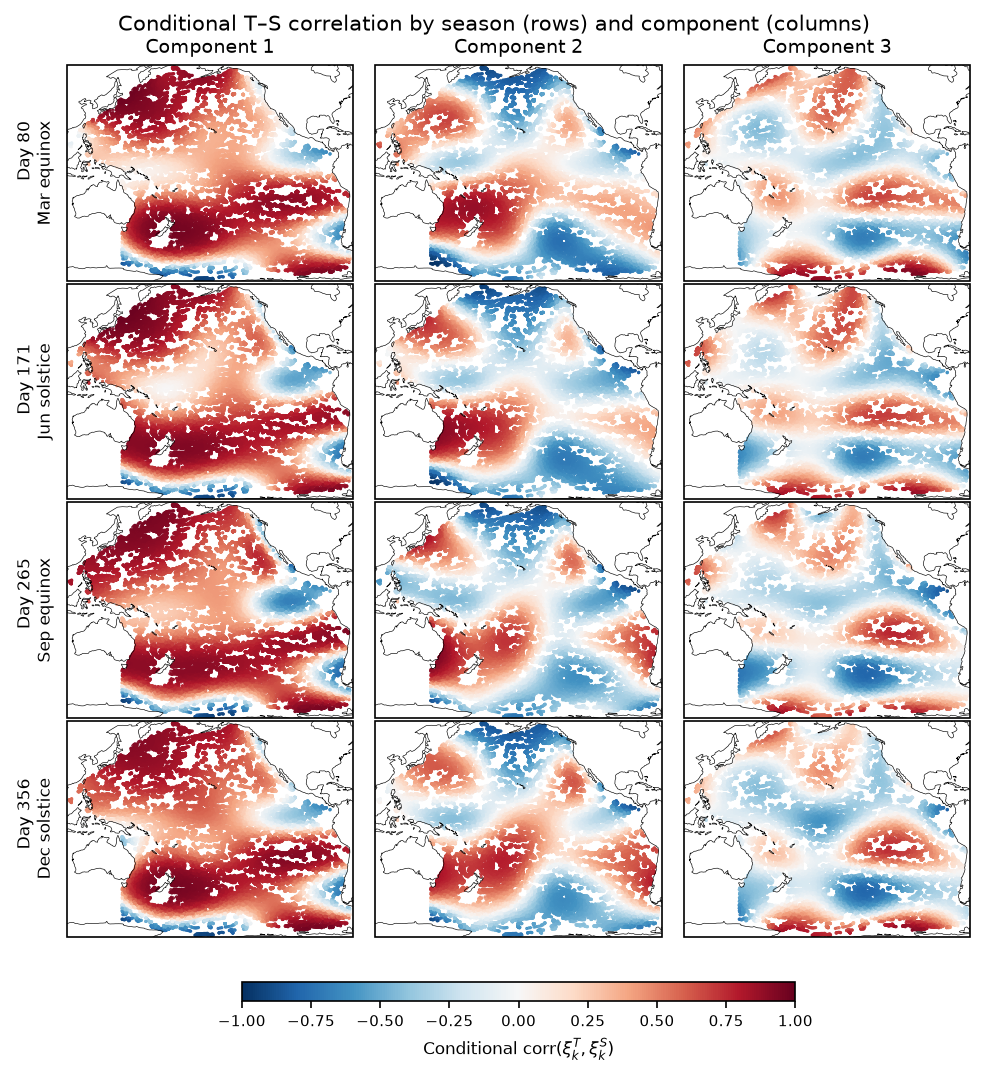

In [6]:
SEASONS = {80: "Mar equinox", 171: "Jun solstice", 265: "Sep equinox", 356: "Dec solstice"}
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(PAGE_W, 7.0), layout="constrained",
                       subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0.01, hspace=0.01)
for i, (dd, name) in enumerate(SEASONS.items()):
    Xd = design(mom_info, covars.assign(day=dd))
    for k in range(3):
        a = ax[i, k]
        a.coastlines(linewidth=0.3)
        a.set_extent([110, 292, -75, 62], crs=ccrs.PlateCarree())
        sc = a.scatter(lon, lat, c=rho_fit[k](Xd), s=0.3, cmap="RdBu_r", vmin=-1, vmax=1,
                       transform=ccrs.PlateCarree(), rasterized=True)
        if i == 0:
            a.set_title(f"Component {k + 1}")
        if k == 0:
            a.text(-0.04, 0.5, f"Day {dd}\n{name}", transform=a.transAxes, rotation=90, ha="right", va="center", fontsize=8)
fig.colorbar(sc, ax=ax, orientation="horizontal", fraction=0.04, shrink=0.6, aspect=30, label=r"Conditional corr$(\xi^T_k, \xi^S_k)$")
fig.suptitle("Conditional T–S correlation by season (rows) and component (columns)", fontsize=10)
fig.savefig(FIG_DIR / "fig2_correlation_maps.png", bbox_inches="tight");


## Uncertainty at selected locations

All values here are for one date, day 80 (the March equinox). For each component $k = 1, \dots, 6$ we take two locations: the observed float locations nearest the 99th and 1st percentiles of $\rho_k$ on that day, between 50°S and 50°N. The sparsely sampled sea-ice edge is left out because the fitted SDs extrapolate there. The table gives $\rho_k$ with its bootstrap SE, a 95% percentile interval, the Wald SE, and the ratio of the two SEs. Every interval excludes zero. For components 4–6 that's a real correlation between differently shaped patterns, not the same anomaly appearing in both variables (see the loadings).


In [7]:
K_SHOW, DAY_FIX = 6, 80
cand = covars[np.abs(covars.lat) <= 50].assign(day=DAY_FIX)   # away from the sea-ice edge and ACC fronts (see text)
rho_cand = np.column_stack([f(design(mom_info, cand)) for f in rho_fit[:K_SHOW]])
rows = []
for k in range(K_SHOW):
    for q, lab in [(0.99, "high"), (0.01, "low")]:
        i = np.argmin(np.abs(rho_cand[:, k] - np.quantile(rho_cand[:, k], q)))
        rows.append(dict(k=k, kind=lab, **cand.iloc[i].to_dict()))
sites = pd.DataFrame(rows)
X_sites_mom = design(mom_info, sites)
est = np.array([rho_fit[k](X_sites_mom[[j]], se=True) for j, k in enumerate(sites.k)])[:, :, 0]
rho_site, se_wald = est[:, 0], est[:, 1]


In [8]:
N_BOOT = 200
CACHE = Path("bootstrap_rho.npz")

def boot_rep(seed):
    # Resample whole profiles; refit mean, SDs and rho_k (k = 1..K_SHOW) with the PCA loadings fixed. Returns rho_k at each site.
    idx = np.random.default_rng(seed).integers(0, len(lat), len(lat))
    Xm, Xs = X_mean[idx], X_mom[idx]
    r = {v: fpca[v]["scores"][idx] - LinearRegression(fit_intercept=False).fit(Xm, fpca[v]["scores"][idx]).predict(Xm) for v in fpca}
    out = np.empty(len(sites))
    for k in range(K_SHOW):
        vT, vS = gamma_var(Xs, r["temp"][:, k] ** 2), gamma_var(Xs, r["psal"][:, k] ** 2)
        f = fit_tanh_corr(Xs, r["temp"][:, k] / np.sqrt(vT(Xs)), r["psal"][:, k] / np.sqrt(vS(Xs)))
        out[(sites.k == k).values] = f(X_sites_mom[(sites.k == k).values])
    return out

site_key = sites[["k", "lat", "lon360", "day"]].to_numpy(float)
cache = np.load(CACHE) if CACHE.exists() else None
if cache is not None and "sites" in cache.files and cache["boot"].shape == (N_BOOT, len(sites)) and np.allclose(cache["sites"], site_key):
    boot = cache["boot"]
else:   # about 2 minutes on 4 workers; delete bootstrap_rho.npz to recompute
    with parallel_config(backend="loky", inner_max_num_threads=1):
        boot = np.array(Parallel(n_jobs=4)(delayed(boot_rep)(b) for b in range(N_BOOT)))
    np.savez(CACHE, boot=boot, sites=site_key)
se_boot = boot.std(0, ddof=1)
lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)

(sites.assign(component=sites.k + 1, rho=rho_site, se_boot=se_boot, ci_2_5=lo, ci_97_5=hi, se_wald=se_wald, ratio=se_boot / se_wald)
      .drop(columns="k").set_index(["component", "kind"]).round(3))


lat   lon360   day    rho  se_boot  ci_2_5  ci_97_5  \
component kind                                                           
1         high -40.610  185.284  80.0  0.955    0.003   0.949    0.960   
          low    6.577  264.577  80.0 -0.511    0.041  -0.583   -0.422   
2         high -31.269  176.118  80.0  0.859    0.011   0.838    0.877   
          low   49.940  211.987  80.0 -0.748    0.018  -0.789   -0.708   
3         high -23.410  238.935  80.0  0.635    0.019   0.594    0.668   
          low  -42.862  231.729  80.0 -0.614    0.021  -0.655   -0.568   
4         high -45.472  276.992  80.0  0.532    0.037   0.467    0.607   
          low   31.990  192.539  80.0 -0.805    0.014  -0.829   -0.775   
5         high  49.909  200.033  80.0  0.588    0.032   0.524    0.651   
          low   -4.500  254.051  80.0 -0.489    0.031  -0.548   -0.426   
6         high  49.593  166.663  80.0  0.349    0.049   0.271    0.447   
          low  -32.727  165.225  80.0 -0.441    0.033  -0.493   -0.376   

                se_wald  ratio  
component kind                  
1         high    0.002  1.367  
          low     0.043  0.968  
2         high    0.008  1.294  
          low     0.015  1.215  
3         high    0.019  1.035  
          low     0.021  1.028  
4         high    0.031  1.204  
          low     0.013  1.109  
5         high    0.034  0.960  
          low     0.026  1.172  
6         high    0.053  0.931  
          low     0.030  1.095

## Seasonality is a surface signal

The fitted mean temperature and salinity profiles at 40°N, 180°, in the mid-latitude North Pacific where the seasonal cycle is strong, on the four dates used in the maps. Top row: temperature. Bottom row: salinity. The left column is the full fitted mean profile. The other columns show what components 1, 2 and 3 each contribute to it, $s\,\hat\xi_k(x)\,\phi_k(d)$ in original units, so the spread between the four colors in a panel is the seasonal cycle carried by that component. The printout under the figure splits the seasonal variation of the fitted mean profile (over all 365 days, summed over depth) into the parts carried by each component.

- **Temperature.** The seasonal cycle is confined to the upper ocean: about ±4 °C at the surface, near zero below about 250 dbar.
- **Salinity.** The cycle is mostly in the upper 250 dbar. There are small departures (≤ 0.02 psu) down to about 1000 dbar, which are probably leakage from the day terms shared across the whole design.
- **Which components carry it.** Seasonality isn't carried by component 1 alone. The seasonal mixed layer is thin (about the top 100 dbar), while component 1 decays smoothly over 600 dbar. Building that sharp shallow shape takes several components: components 1, 2 and 4 for temperature, and mostly component 4 for salinity. Individually, components 2 and 3 vary with season well below 250 dbar, by up to about 1 °C at 300 dbar, but those deep pieces cancel in the sum, so the full profile shows no seasonal change at depth.


temp: share of seasonal variation in the mean profile by component: 1: 31% 2: 23% 3: 11% 4: 18% 5: 10% 6: 4% 7: 1% 8: 1% 10: 1%
psal: share of seasonal variation in the mean profile by component: 1: 13% 2: 2% 3: 11% 4: 47% 5: 7% 6: 12% 7: 7% 8: 1%


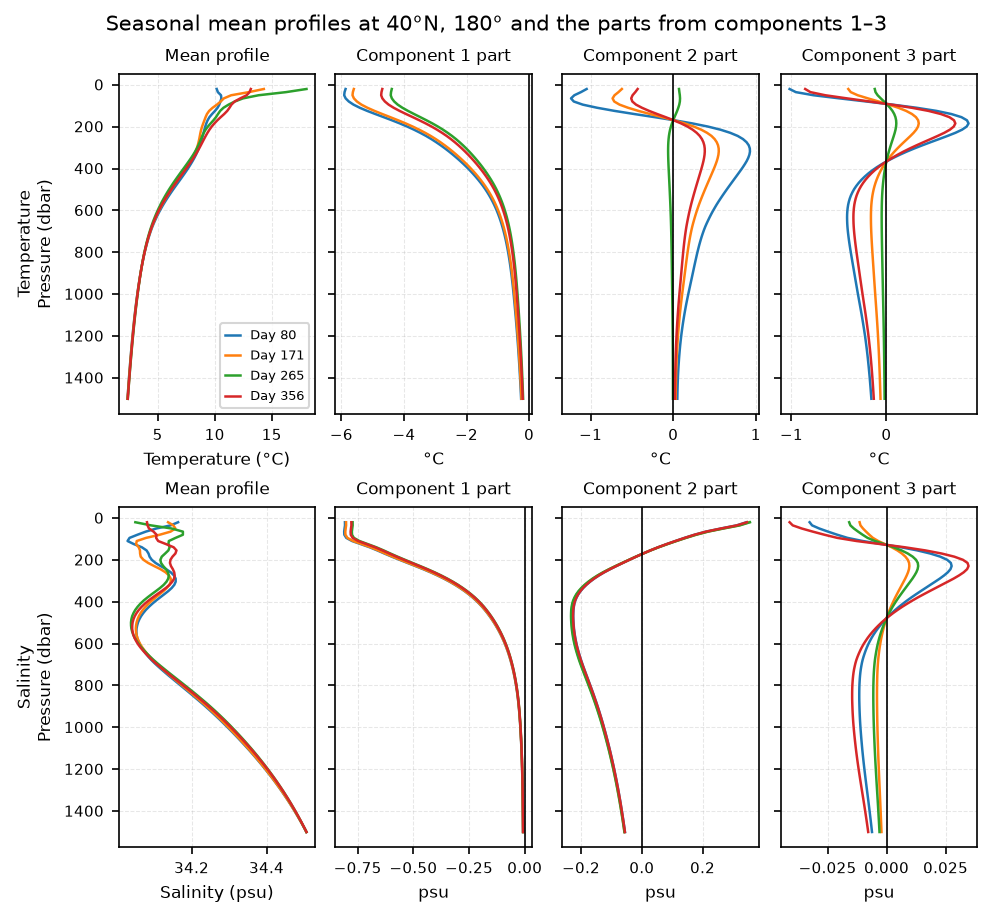

In [9]:
LOC = dict(lat=40.0, lon360=180.0)
Xq = design(mean_info, pd.DataFrame([dict(LOC, day=d) for d in SEASONS]))
Xyear = design(mean_info, pd.DataFrame([dict(LOC, day=d) for d in range(1, 366)]))

fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(PAGE_W, 6.0), sharey=True, layout="constrained")
for r, (v, unit) in enumerate([("temp", "°C"), ("psal", "psu")]):
    f = fpca[v]
    sc_hat = mean_fit[v].predict(Xq)                                  # fitted scores, (4 dates, K)
    prof = f["m"] + f["s"] * (f["pca"].mean_ + sc_hat @ f["pca"].components_)
    for i, (dd, name) in enumerate(SEASONS.items()):
        ax[r, 0].plot(prof[i], pressure, color=f"C{i}", linewidth=1.2, label=f"Day {dd}")
        for k in range(3):
            ax[r, k + 1].plot(f["s"] * sc_hat[i, k] * f["pca"].components_[k], pressure, color=f"C{i}", linewidth=1.2)
    ax[r, 0].set_xlabel(f"{'Temperature' if v == 'temp' else 'Salinity'} ({unit})")
    ax[r, 0].set_title("Mean profile", fontsize=8)
    for k in range(3):
        ax[r, k + 1].axvline(0, color="black", linewidth=0.8)
        ax[r, k + 1].set_title(f"Component {k + 1} part", fontsize=8); ax[r, k + 1].set_xlabel(unit)
    ax[r, 0].set_ylabel(f"{'Temperature' if v == 'temp' else 'Salinity'}\nPressure (dbar)")
    seas_var = mean_fit[v].predict(Xyear).var(0)          # seasonal variance of each fitted score at LOC
    print(f"{v}: share of seasonal variation in the mean profile by component:",
          " ".join(f"{k + 1}: {x:.0%}" for k, x in enumerate(seas_var / seas_var.sum()) if x >= 0.005))
for a in ax.flat:
    a.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax[0, 0].invert_yaxis(); ax[0, 0].legend(loc="lower right", fontsize=6, handlelength=1.2)
fig.suptitle("Seasonal mean profiles at 40°N, 180° and the parts from components 1–3", fontsize=10)
fig.savefig(FIG_DIR / "fig3_seasonality.png", bbox_inches="tight");
